# Práctica 4 - Visión por Computador

## Marcial Galván - Alejandra Rodríguez

En este cuaderno se juntan los tres módulos de la práctica en un único prototipo que procesa un vídeo y:

1. detecta y sigue a las personas y los vehículos, con **RT-DETRv4-L** (pesos de COCO), (tras un estudio de detectores, ubicado en [`det_module1_comparative.ipynb`](./det_module1_comparative.ipynb)), y **ByteTrack**, tras consultar distintas fuentes ([README](./README.md#elección-de-tracker));
2. detecta la matrícula de cada vehículo con el **RT-DETRv4-L entrenado** (tras un estudio de detectores de matrículas, en [`plates_module2_comparative.ipynb`](./plates_module2_comparative.ipynb));
3. lee el texto de cada matrícula con **PaddleOCR** (tras un estudio de OCR, en [`ocr_module3_comparative.ipynb`](./ocr_module3_comparative.ipynb));
4. cuenta el total de cada clase y el flujo de personas y vehículos según la dirección en la que salen de la escena.

## Vídeos de salida

A partir del mismo vídeo de entrada se generan dos vídeos, cada uno con su CSV de resultados:

- **Vídeo anonimizado**: cara y matrículas borrosas
- **OCR**: detección de personas y coches, con lectura de matrículas

En la cabecera de los dos vídeos se muestra en todo momento el número de personas, vehículos y matrículas distintos que se han visto, y el flujo de personas y de vehículos en cada dirección.

Procesar un vídeo completo tarda varios minutos, por lo que cada vídeo se calcula una sola vez, mostrándolo en directo mientras se procesa, y se guarda en `results/video/` junto con su CSV y su resumen. En las siguientes ejecuciones se reutiliza el resultado guardado, a no ser que se indique `FORCE = True`.

## Índice

1. [Preparación](#1-preparación)
    - [1.1 Configuración](#11-configuración)
    - [1.2 Parámetros](#12-parámetros)
    - [1.3 Información del equipo](#13-información-del-equipo)
2. [Detector de personas y vehículos](#2-detector-de-personas-y-vehículos)
    - [2.1 Detección](#21-detección)
    - [2.2 Prueba sobre una imagen](#22-prueba-sobre-una-imagen)
3. [Detector de matrículas](#3-detector-de-matrículas)
    - [3.1 Recortes de los vehículos](#31-recortes-de-los-vehículos)
    - [3.2 Detección](#32-detección)
    - [3.3 Anonimización](#33-anonimización)
    - [3.4 Prueba sobre una imagen](#34-prueba-sobre-una-imagen)
4. [Lectura de las matrículas](#4-lectura-de-las-matrículas)
    - [4.1 PaddleOCR](#41-paddleocr)
    - [4.2 Prueba sobre una imagen](#42-prueba-sobre-una-imagen)
5. [Seguimiento](#5-seguimiento)
    - [5.1 ByteTrack](#51-bytetrack)
    - [5.2 Recuento y flujo](#52-recuento-y-flujo)
    - [5.3 Lectura de cada vehículo](#53-lectura-de-cada-vehículo)
6. [Procesado del vídeo](#6-procesado-del-vídeo)
    - [6.1 Análisis de un fotograma](#61-análisis-de-un-fotograma)
    - [6.2 Dibujo de los resultados](#62-dibujo-de-los-resultados)
    - [6.3 Cabecera](#63-cabecera)
    - [6.4 CSV](#64-csv)
    - [6.5 Procesado y guardado](#65-procesado-y-guardado)
7. [Vídeo 1: detección y anonimización](#7-vídeo-1-detección-y-anonimización)
8. [Vídeo 2: detección y OCR](#8-vídeo-2-detección-y-ocr)
9. [Conclusiones](#9-conclusiones)

## 1. Preparación

### 1.1 Configuración

El código común a varios cuadernos está en [`common/`](./common): rutas, detectores, OCR, normalización de las lecturas e información del equipo:

In [1]:
import json
import time
from collections import Counter, defaultdict

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ultralytics.cfg import ROOT as ULTRALYTICS_ROOT
from ultralytics.engine.results import Boxes
from ultralytics.trackers.byte_tracker import BYTETracker
from ultralytics.utils import YAML, IterableSimpleNamespace

from common.detectors import DetrDetector, ObjectDetector
from common.detr import boxes_to_pixels, preprocess
from common.ocr import PaddleOCRModel
from common.paths import PLATES_RUNS, ROOT
from common.plate_text import normalize
from common.specs import save_system_info

Rutas del detector de matrículas entrenado, de la imagen y el vídeo de entrada y de los resultados:

In [2]:
PLATE_RUN = PLATES_RUNS / "rtdetrv4_l"
PLATE_WEIGHTS = PLATE_RUN / "best_stg1.pth"
OUTPUT = ROOT / "results" / "video"
IMAGE = ROOT / "test.jpg"
VIDEO = ROOT / "C0142.MP4"

OUTPUT.mkdir(parents=True, exist_ok=True)
if not PLATE_WEIGHTS.exists():
    raise FileNotFoundError(f"No existe {PLATE_WEIGHTS}: ejecuta antes plates_module2/train_plate_detectors.ipynb")

### 1.2 Parámetros

- `CLASSES`: clases de COCO que se buscan (persona, coche, moto, autobús y camión) y su nombre en el vídeo y en el CSV: `persona` o `vehiculo`.
- `DET_CONF`: confianza mínima de una clasificación para dibujarlo en la imagen.
- `TRACK_MIN_SCORE` y `TRACKER_OVERRIDES`: confianza mínima de las detecciones que recibe ByteTrack, y cambios sobre su configuración por defecto.
- `MARGIN`: margen alrededor de cada vehículo al recortarlo para buscar su matrícula, el mismo con el que se generó el conjunto de entrenamiento ([`build_vehicle_dataset.ipynb`](./plates_module2/build_vehicle_dataset.ipynb)).
- `MIN_CROP_SIDE`: lado mínimo, en píxeles, de un recorte de vehículo o de matrícula.
- `PLATE_CONF`: confianza mínima en la detección de una matrícula.
- `MIN_PLATE_CHARS`: número mínimo de caracteres de una lectura para considerarla una matrícula válida.
- `LOCK_FRAMES`: lecturas seguidas e iguales tras las que se da por válida la matrícula de un vehículo.
- `HEAD_RATIO`: parte superior de la caja de cada persona, que se desenfoca al anonimizar.
- `MIN_MOVE`: desplazamiento mínimo, en proporción al tamaño del fotograma, para considerar que un objeto se ha movido.
- `SHOW`: si es `True`, el vídeo se muestra en una ventana mientras se procesa (**ESC** para pararlo).
- `FORCE`: si es `False` y un vídeo ya está procesado, se reutiliza el resultado guardado.

In [3]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLASSES = {0: "persona", 2: "vehiculo", 3: "vehiculo", 5: "vehiculo", 7: "vehiculo"}
PERSON = 0
DET_CONF = 0.5
TRACK_MIN_SCORE = 0.1
TRACKER_OVERRIDES = {"new_track_thresh": 0.5}
MARGIN = 0.15
MIN_CROP_SIDE = 8
PLATE_CONF = 0.5
MIN_PLATE_CHARS = 4
LOCK_FRAMES = 10
HEAD_RATIO = 0.3
MIN_MOVE = 0.05
SHOW = True
FORCE = False

print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(sin GPU)")

device: cuda NVIDIA GeForce RTX 5080


### 1.3 Información del equipo

La velocidad del procesado depende del equipo, por lo que se guarda esta información en `system_info.json` (ver funciones en [`common/specs.py`](./common/specs.py)):

In [4]:
PACKAGES = ["torch", "torchvision", "ultralytics", "paddlepaddle-gpu", "paddleocr", "opencv-python", "numpy", "pandas"]

save_system_info(OUTPUT / "system_info.json", PACKAGES)

{'os': 'Windows-10-10.0.26200-SP0',
 'cpu': 'AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD',
 'cpu_cores': 8,
 'ram_gb': 34.0,
 'python': '3.11.18',
 'gpu': 'NVIDIA GeForce RTX 5080',
 'gpu_driver': '610.88',
 'cuda': '13.0',
 'packages': {'torch': '2.14.1+cu130',
  'torchvision': '0.29.1+cu130',
  'ultralytics': '8.4.202',
  'paddlepaddle-gpu': '3.4.0',
  'paddleocr': '3.7.0',
  'opencv-python': '4.10.0.84',
  'numpy': '2.3.5',
  'pandas': '3.1.1'}}

## 2. Detector de personas y vehículos

### 2.1 Detección

Se utiliza RT-DETRv4-L con los pesos de COCO, el detector elegido en [`det_module1_comparative.ipynb`](./det_module1_comparative.ipynb). Si el modelo no está en el equipo, descarga el repositorio oficial y los pesos, y construye el modelo igual que en la comparativa. Recibe una imagen BGR y devuelve las cajas `[x1, y1, x2, y2]` en píxeles, su confianza y su clase:

- Para cada caja, elige su clasificación en función de su confianza. Así, un mismo objeto no aparece dos veces, por ejemplo como coche y como camión.
- Se conservan las cajas con confianza ≥ `TRACK_MIN_SCORE`, ya que ByteTrack también usa las de confianza baja, y la NMS descarta los duplicados con un IoU superior a 70 %.

In [5]:
detector = ObjectDetector(list(CLASSES), TRACK_MIN_SCORE, device=DEVICE)
print("Detectando:", sorted(set(CLASSES.values())))

Detectando: ['persona', 'vehiculo']


### 2.2 Prueba sobre una imagen

Antes de procesar el vídeo, se comprueba el detector sobre la imagen de _test_ del README de la práctica (`IMAGE`), con las detecciones de confianza ≥ `DET_CONF`:

In [6]:
FONT = cv2.FONT_HERSHEY_SIMPLEX
WHITE, BLACK = (255, 255, 255), (0, 0, 0)
CLASS_COLORS = {"persona": (0, 200, 0), "vehiculo": (0, 140, 255)}
PLATE_COLOR = (60, 255, 60)


def font_scale(image):
    return max(0.5, image.shape[1] / 1600)


def put_text(image, text, x, y, scale, color=WHITE, background=None):
    thickness = max(1, round(2 * scale))
    (w, h), base = cv2.getTextSize(text, FONT, scale, thickness)
    if background is not None:
        cv2.rectangle(image, (x, y - h - base), (x + w + 4, y + base), background, -1)
    cv2.putText(image, text, (x + 2, y), FONT, scale, color, thickness, cv2.LINE_AA)
    return x + w + 4


def text_height(text, scale):
    (_, h), base = cv2.getTextSize(text, FONT, scale, max(1, round(2 * scale)))
    return h + base

In [7]:
def draw_box(image, box, color, text=None):
    x1, y1, x2, y2 = (int(v) for v in box)
    scale = font_scale(image)
    cv2.rectangle(image, (x1, y1), (x2, y2), color, max(2, round(3 * scale)))
    if text:
        label_scale = 0.8 * scale
        put_text(image, text, x1, max(y1 - 4, text_height(text, label_scale)), label_scale, BLACK, background=color)


def show_images(images, titles, size=8):
    plt.figure(figsize=(size * len(images), size * 0.6))
    for i, (image, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

Counter({'vehiculo': 7, 'persona': 3})


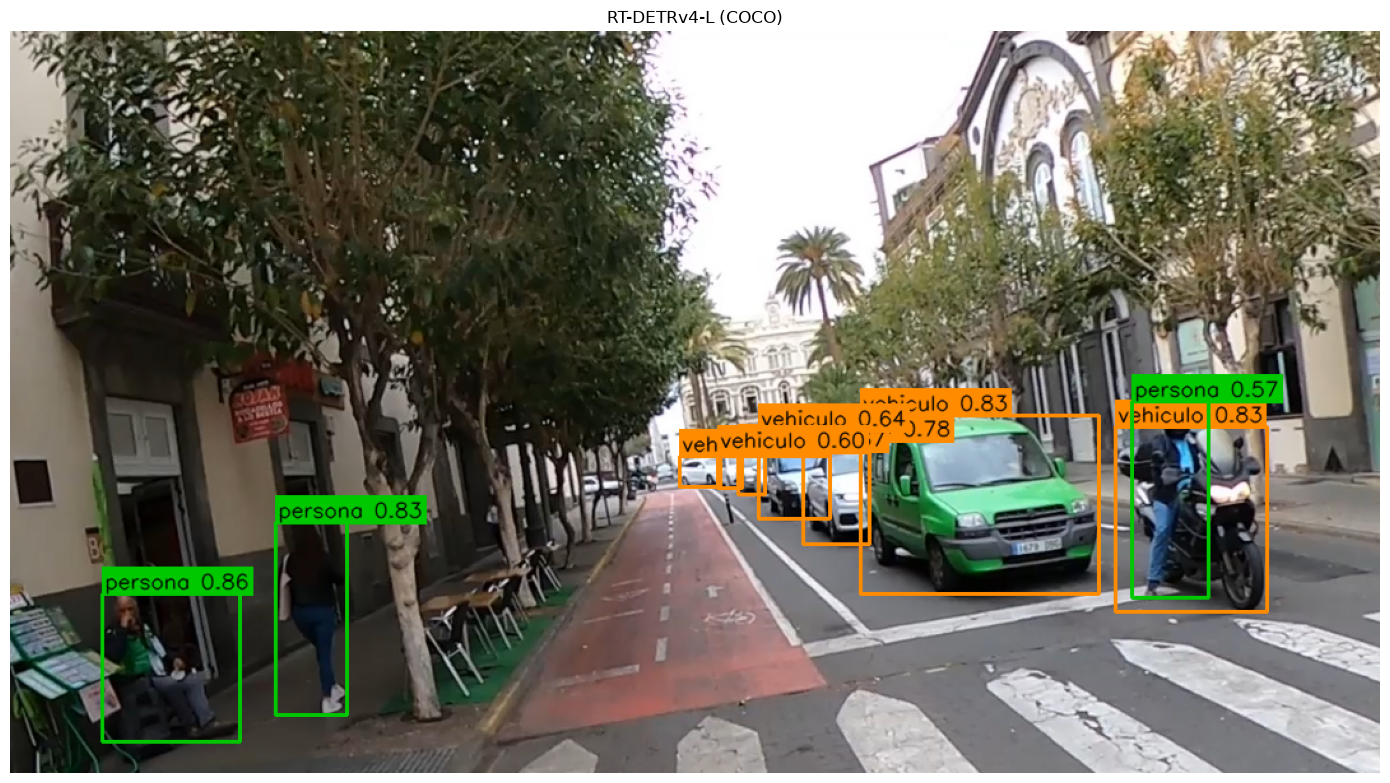

In [8]:
image = cv2.imread(str(IMAGE))
boxes, scores, labels = detector(image)
confident = scores >= DET_CONF
boxes, scores, labels = boxes[confident], scores[confident], labels[confident]

detections = image.copy()
for box, score, label in zip(boxes, scores, labels):
    draw_box(detections, box, CLASS_COLORS[CLASSES[label]], f"{CLASSES[label]} {score:.2f}")

print(Counter(CLASSES[label] for label in labels))
show_images([detections], ["RT-DETRv4-L (COCO)"], size=14)

## 3. Detector de matrículas

### 3.1 Recortes de los vehículos

El detector de matrículas no trabaja sobre el fotograma completo, sino sobre el recorte de cada vehículo, con un margen, igual que en el entrenamiento:

In [9]:
def expand_box(box, width, height):
    x1, y1, x2, y2 = box
    mx, my = MARGIN * (x2 - x1), MARGIN * (y2 - y1)
    return max(0, int(x1 - mx)), max(0, int(y1 - my)), min(width, int(x2 + mx)), min(height, int(y2 + my))


def crop(image, box):
    height, width = image.shape[:2]
    x1, y1, x2, y2 = (int(round(v)) for v in box)
    return image[max(0, y1):min(height, y2), max(0, x1):min(width, x2)]


def is_valid_crop(crop_bgr):
    return min(crop_bgr.shape[:2]) >= MIN_CROP_SIDE

### 3.2 Detección

`PlateDetector` que construye un modelo con la configuración de su entrenamiento (`config.yml`) y los pesos de la mejor época, igual que en la comparativa de detectores matrículas. A diferencia de `DetrDetector`, que procesa las imágenes de una en una, `PlateDetector` reescala todos los recortes de un fotograma a 640 × 640 y los pasa juntos al modelo, en un único _batch_, que es más rápido.

Como solo hay una clase, la confianza de cada _query_ es directamente la de `plate`, y en cada recorte se queda la matrícula de mayor confianza. Devuelve, para cada recorte, la caja de su matrícula, en píxeles del recorte, y su confianza:

In [10]:
class PlateDetector(DetrDetector):
    def __init__(self):
        super().__init__("rtdetrv4l-best", "rtdetrv4", PLATE_RUN / "config.yml", PLATE_WEIGHTS, DEVICE)

    @torch.inference_mode()
    def __call__(self, crops):
        if not crops:
            return np.zeros((0, 4)), np.zeros(0)
        outputs = self.model(torch.cat([preprocess(c, self.size_hw, self.device) for c in crops]))
        scores, queries = outputs["pred_logits"][..., 0].sigmoid().max(-1)
        boxes = outputs["pred_boxes"][torch.arange(len(crops), device=self.device), queries]
        pixels = torch.stack([boxes_to_pixels(box, c.shape[1], c.shape[0]) for box, c in zip(boxes, crops)])
        return pixels.cpu().numpy(), scores.cpu().numpy()


plate_detector = PlateDetector()

`find_plates` recorta los vehículos de una imagen, busca su matrícula y pasa las cajas a coordenadas de la imagen completa. Devuelve un diccionario con la posición de cada vehículo en la lista y su matrícula (caja, confianza y texto, aún vacío), solo para los vehículos en los que existe una matrícula con confianza ≥ `PLATE_CONF`:

In [11]:
def find_plates(image, vehicle_boxes):
    height, width = image.shape[:2]
    regions = [expand_box(box, width, height) for box in vehicle_boxes]
    valid = [i for i, region in enumerate(regions) if is_valid_crop(crop(image, region))]
    boxes, scores = plate_detector([crop(image, regions[i]) for i in valid])

    plates = {}
    for i, box, score in zip(valid, boxes, scores):
        if score >= PLATE_CONF:
            x1, y1 = regions[i][:2]
            plates[i] = {"box": box + [x1, y1, x1, y1], "score": float(score), "text": ""}
    return plates

### 3.3 Anonimización

Para anonimizar sin segmentar, se desenfoca:

- **Personas:** el `HEAD_RATIO` (30 %) superior de su caja, donde suele estar la cara.
- **Matrículas:** la caja completa.

El desenfoque es gaussiano y proporcional al tamaño de la zona, por lo que una matrícula pequeña se desenfoca tanto como una cara grande.

In [12]:
def head_box(box):
    x1, y1, x2, y2 = box
    return x1, y1, x2, y1 + HEAD_RATIO * (y2 - y1)


def blur(image, box):
    region = crop(image, box)
    if region.size:
        region[:] = cv2.GaussianBlur(region, (0, 0), max(region.shape[:2]) / 4)


def anonymize(image, people_boxes, plate_boxes):
    for box in people_boxes:
        blur(image, head_box(box))
    for box in plate_boxes:
        blur(image, box)

### 3.4 Prueba sobre una imagen

Matrículas encontradas en los vehículos de la imagen de prueba, y la misma imagen anonimizada:

1 matrículas en 7 vehículos


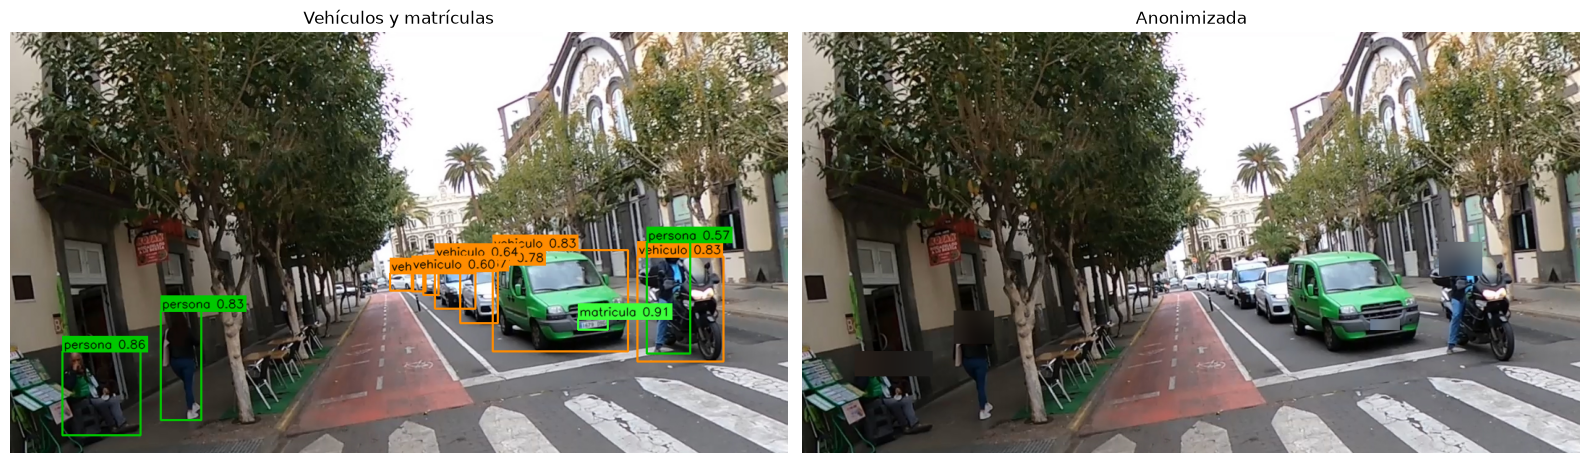

In [13]:
vehicle_boxes = boxes[labels != PERSON]
people_boxes = boxes[labels == PERSON]
plates = find_plates(image, vehicle_boxes)

with_plates = detections.copy()
for plate in plates.values():
    draw_box(with_plates, plate["box"], PLATE_COLOR, f"matricula {plate['score']:.2f}")

anonymized = image.copy()
anonymize(anonymized, people_boxes, [plate["box"] for plate in plates.values()])

print(f"{len(plates)} matrículas en {len(vehicle_boxes)} vehículos")
show_images([with_plates, anonymized], ["Vehículos y matrículas", "Anonimizada"])

## 4. Lectura de las matrículas

### 4.1 PaddleOCR

Se utiliza PaddleOCR, el OCR elegido en la comparativa ([`ocr_module3_comparative.ipynb`](./ocr_module3_comparative.ipynb)). Como ya se sabe dónde está la matrícula, solo se utiliza su módulo de reconocimiento de texto.

La clase de PaddleOCR (`PaddleOCRModel`) y la normalización de la lectura (`normalize`: mayúsculas y sin espacios, guiones ni otros caracteres no alfanuméricos) son las mismas que en la comparativa ([`ocr.py`](./common/ocr.py) y [`plate_text.py`](./common/plate_text.py)). Además, se descarta toda lectura de menos de `MIN_PLATE_CHARS` (4) caracteres:

In [14]:
def is_valid_plate(text):
    return len(text) >= MIN_PLATE_CHARS

La clase `PlateReader` recibe el recorte BGR de una matrícula y devuelve su texto normalizado. Si el recorte es demasiado pequeño, o si la lectura tiene menos de 4 caracteres, devuelve una cadena vacía y no se escribe nada sobre la matrícula:

In [15]:
class PlateReader:
    def __init__(self):
        self.ocr = PaddleOCRModel()
        self.ocr.load()

    def __call__(self, crop_bgr):
        if not is_valid_crop(crop_bgr):
            return ""
        text = normalize(self.ocr.read(crop_bgr))
        return text if is_valid_plate(text) else ""


reader = PlateReader()

### 4.2 Prueba sobre una imagen

El texto de cada matrícula se escribe sobre el borde superior de su caja:

In [16]:
def draw_plate(image, plate):
    x1, y1, x2, y2 = (int(v) for v in plate["box"])
    scale = font_scale(image)
    cv2.rectangle(image, (x1, y1), (x2, y2), PLATE_COLOR, max(2, round(2 * scale)))
    if plate["text"]:
        _, base = cv2.getTextSize(plate["text"], FONT, scale, max(1, round(2 * scale)))
        put_text(image, plate["text"], x1, max(y1 - base - 1, text_height(plate["text"], scale)), scale, BLACK, background=PLATE_COLOR)

['16790K3']


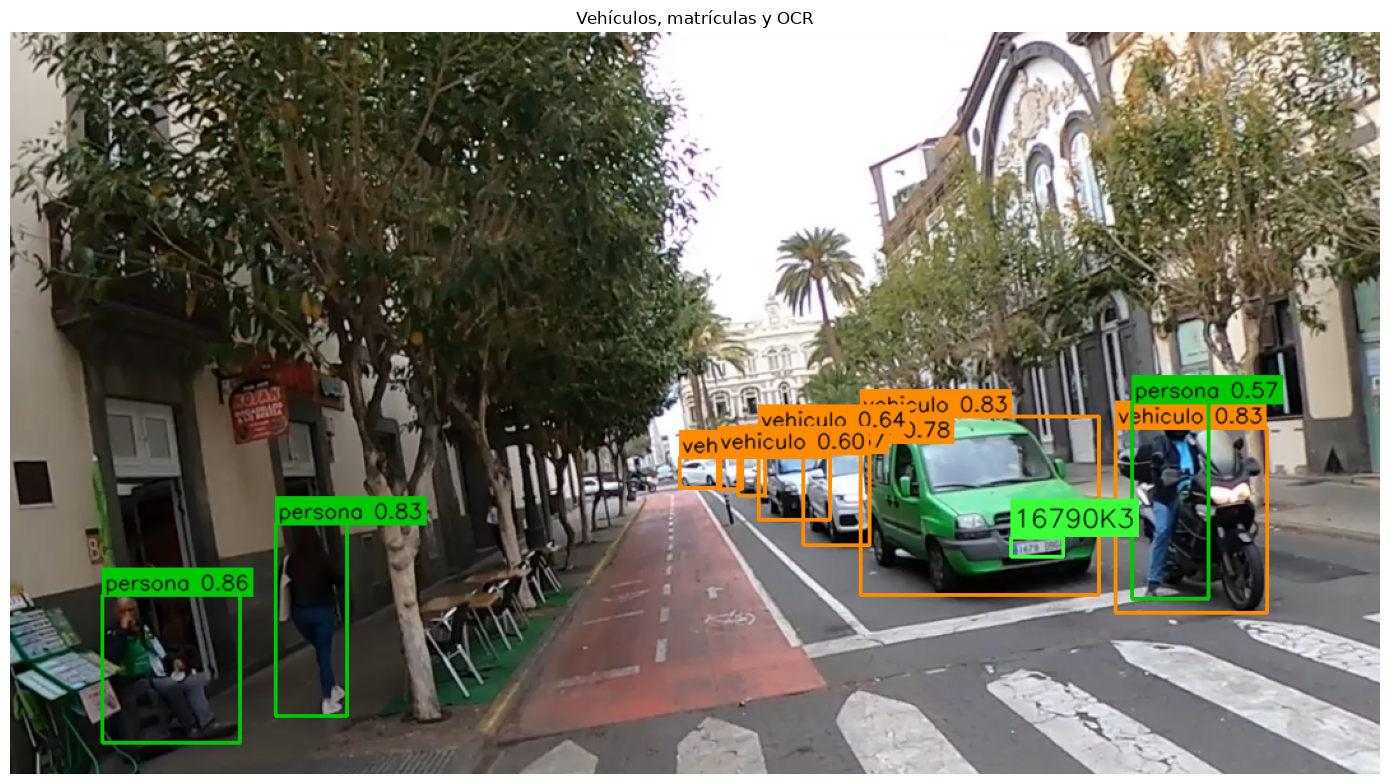

In [17]:
plates = {i: {**plate, "text": reader(crop(image, plate["box"]))} for i, plate in plates.items()}

with_text = detections.copy()
for plate in plates.values():
    draw_plate(with_text, plate)

print([plate["text"] for plate in plates.values()])
show_images([with_text], ["Vehículos, matrículas y OCR"], size=14)

## 5. Seguimiento

### 5.1 ByteTrack

Se utiliza ByteTrack, de Ultralytics. ByteTrack asocia las detecciones de cada fotograma con los objetos que ya se estaban siguiendo usando su **posición y movimiento** (predicciones de filtro de Kalman). Un objeto que deja de verse se conserva `track_buffer` fotogramas (30) antes de darlo por perdido.

Con el valor por defecto de `new_track_thresh` (0,25), los objetos pequeños o lejanos que aparecen y desaparecen reciben un identificador nuevo cada vez que reaparecen, y el recuento de objetos distintos se dispara. Con 0,5, solo se crean identificadores nuevos para cambios evidentes en las detecciones.

`new_tracker` crea un ByteTrack con la configuración de Ultralytics (`bytetrack.yaml`) y los cambios de `TRACKER_OVERRIDES`. `update_tracker` recibe las detecciones de un fotograma, y devuelve los objetos _trackeados_ en él, cada uno con su caja, su identificador, su confianza y su clase:

In [18]:
def new_tracker():
    cfg = {**YAML.load(ULTRALYTICS_ROOT / "cfg/trackers/bytetrack.yaml"), **TRACKER_OVERRIDES}
    return BYTETracker(IterableSimpleNamespace(**cfg))


def update_tracker(tracker, boxes, scores, labels, frame):
    detections = np.column_stack([boxes, scores, labels]).astype(np.float32)
    rows = tracker.update(Boxes(detections, frame.shape[:2]), frame)
    return [{"box": r[:4], "id": int(r[4]), "score": float(r[5]), "label": int(r[6])} for r in rows]

### 5.2 Recuento y flujo

`FlowCounter` guarda, para cada identificador, su primera y su última posición, el último fotograma en el que se ha visto y las clases con las que se ha detectado. Un objeto puede detectarse en algunos fotogramas con otra clase (por ejemplo, un vehículo lejano como persona), por lo que se le asigna la clase con la que se ha detectado más veces.

El **flujo** de un objeto es la dirección en la que se ha desplazado desde que apareció hasta que salió de la escena: izquierda, derecha, arriba o abajo, según el eje en el que más se haya movido. Si se ha movido menos de `MIN_MOVE` (5 % del fotograma), se cuenta como parado. Un objeto ha salido de la escena cuando ByteTrack lo da por perdido, al no verse durante `track_buffer` fotogramas, o al terminar el vídeo:

In [19]:
GROUPS = tuple(dict.fromkeys(CLASSES.values()))
DIRECTIONS = ("izquierda", "derecha", "arriba", "abajo", "parado")


def center(box):
    return (box[0] + box[2]) / 2, (box[1] + box[3]) / 2


def direction(start, end, width, height):
    dx, dy = (end[0] - start[0]) / width, (end[1] - start[1]) / height
    if max(abs(dx), abs(dy)) < MIN_MOVE:
        return "parado"
    if abs(dx) >= abs(dy):
        return "derecha" if dx > 0 else "izquierda"
    return "abajo" if dy > 0 else "arriba"

In [20]:
class FlowCounter:
    def __init__(self, width, height, lost_frames):
        self.size = (width, height)
        self.lost_frames = lost_frames
        self.first, self.last, self.last_seen = {}, {}, {}
        self.groups = defaultdict(Counter)
        self.flow = {group: Counter() for group in GROUPS}
        self.finished = set()

    def update(self, tracks, frame_idx):
        for t in tracks:
            c = center(t["box"])
            self.first.setdefault(t["id"], c)
            self.last[t["id"]] = c
            self.last_seen[t["id"]] = frame_idx
            self.groups[t["id"]][CLASSES[t["label"]]] += 1
        for track_id, seen in self.last_seen.items():
            if frame_idx - seen > self.lost_frames and track_id not in self.finished:
                self.finish(track_id)

    def group(self, track_id):
        return self.groups[track_id].most_common(1)[0][0]

    def finish(self, track_id):
        d = direction(self.first[track_id], self.last[track_id], *self.size)
        self.flow[self.group(track_id)][d] += 1
        self.finished.add(track_id)

    def finish_all(self):
        for track_id in set(self.last_seen) - self.finished:
            self.finish(track_id)

    def totals(self):
        return Counter(self.group(i) for i in self.groups)

### 5.3 Lectura de cada vehículo

La lectura de una matrícula puede cambiar de un fotograma a otro (por el desenfoque, el ángulo o la distancia). Como cada matrícula pertenece a un vehículo con su identificador, se guardan todas las lecturas válidas de cada vehículo y se muestra la más repetida, que es mucho más estable que la de un único fotograma.

Además, cuando un vehículo acumula `LOCK_FRAMES` (10) lecturas seguidas e iguales, su matrícula se da por válida, fijándola y dejando de llamar al OCR para leerla. Su matrícula se sigue detectando en cada fotograma y se sigue escribiendo el mismo texto, como si siguiera pasando por el OCR.

In [21]:
class PlateVotes:
    def __init__(self):
        self.votes = defaultdict(Counter)
        self.streaks = {}
        self.locked = {}

    def add(self, track_id, text):
        if track_id in self.locked:
            return
        if not is_valid_plate(text):
            self.streaks.pop(track_id, None)
            return
        self.votes[track_id][text] += 1
        last, count = self.streaks.get(track_id, ("", 0))
        count = count + 1 if text == last else 1
        self.streaks[track_id] = (text, count)
        if count >= LOCK_FRAMES:
            self.locked[track_id] = text

    def best(self, track_id, fallback):
        if track_id in self.locked:
            return self.locked[track_id]
        votes = self.votes.get(track_id)
        return votes.most_common(1)[0][0] if votes else fallback

    def readings(self):
        return {track_id: self.best(track_id, "") for track_id in self.votes}

## 6. Procesado del vídeo

### 6.1 Análisis de un fotograma

`new_state` crea un diccionario con todo lo que se acumula a lo largo de un vídeo: el _tracker_, el recuento y el flujo (`FlowCounter`), las lecturas de cada vehículo (`PlateVotes`), los vehículos con matrícula y las filas del CSV:

In [22]:
def new_state(width, height, reader):
    tracker = new_tracker()
    return {"tracker": tracker, "flow": FlowCounter(width, height, tracker.max_frames_lost), "reader": reader,
            "votes": PlateVotes(), "plate_ids": set(), "rows": []}

Cada fotograma se analiza en tres pasos:

1. `track_objects`: detecta las personas y los vehículos y actualiza el _tracker_. Para anonimizar, se usan tanto las personas seguidas como las detectadas con confianza ≥ `DET_CONF`, pues ByteTrack no realiza seguimiento hasta el segundo fotograma, y así ninguna persona queda sin anonimizar.
2. `track_plates`: busca la matrícula de cada vehículo seguido y, si hay `reader` y no se ha validado, la lee. La matrícula se asocia al identificador de su vehículo.
3. `analyze_frame`: actualiza el recuento, el flujo y las lecturas, sustituye cada lectura por la más repetida de su vehículo y añade las filas del CSV. Devuelve los objetos _trackeados_, las personas que se anonimizan y las matrículas.

In [23]:
def track_objects(frame, tracker):
    boxes, scores, labels = detector(frame)
    tracks = update_tracker(tracker, boxes, scores, labels, frame)
    detected = [box for box, score, label in zip(boxes, scores, labels) if label == PERSON and score >= DET_CONF]
    return tracks, detected + [t["box"] for t in tracks if t["label"] == PERSON]


def track_plates(frame, tracks, reader, locked):
    vehicles = [t for t in tracks if t["label"] != PERSON]
    plates = {}
    for i, plate in find_plates(frame, [t["box"] for t in vehicles]).items():
        track_id = vehicles[i]["id"]
        text = reader(crop(frame, plate["box"])) if reader and track_id not in locked else ""
        plates[track_id] = {**plate, "text": text}
    return plates

In [24]:
def analyze_frame(frame, frame_idx, state):
    tracks, people = track_objects(frame, state["tracker"])
    plates = track_plates(frame, tracks, state["reader"], state["votes"].locked)

    state["flow"].update(tracks, frame_idx)
    state["plate_ids"].update(plates)
    for track_id, plate in plates.items():
        state["votes"].add(track_id, plate["text"])
    plates = {i: {**plate, "text": state["votes"].best(i, plate["text"])} for i, plate in plates.items()}

    state["rows"] += csv_rows(frame_idx, tracks, plates, state["flow"])
    return {"tracks": tracks, "people": people, "plates": plates}

### 6.2 Dibujo de los resultados

Cada objeto _trackeado_ tiene siempre el mismo color, que depende de su id, y se dibuja junto a su caja, su clase y su identificador:

In [25]:
def id_color(track_id):
    return tuple(int(c) for c in np.random.RandomState(track_id).randint(60, 255, 3))


def draw_tracks(image, tracks, flow):
    for t in tracks:
        draw_box(image, t["box"], id_color(t["id"]), f"{flow.group(t['id'])} #{t['id']}")

Los dos vídeos solo se diferencian en cómo se muestran las personas y las matrículas:

- `render_anonymized`: desenfoca la cabeza de las personas y las matrículas, antes de dibujar las cajas.
- `render_ocr`: dibuja la caja de cada matrícula con su lectura sobre el borde superior.

In [26]:
def render_anonymized(frame, result, flow):
    anonymize(frame, result["people"], [plate["box"] for plate in result["plates"].values()])
    draw_tracks(frame, result["tracks"], flow)


def render_ocr(frame, result, flow):
    draw_tracks(frame, result["tracks"], flow)
    for plate in result["plates"].values():
        draw_plate(frame, plate)

### 6.3 Cabecera

Encima de cada fotograma se añade una cabecera con cuatro líneas:

1. Personas, vehículos y matrículas distintos vistos hasta el momento.
2. Objetos en escena, fotograma actual y velocidad de procesado.
3. Flujo de personas y vehículos: cuántas han salido hacia cada dirección (flechas) y cuántas se han quedado paradas (círculo).

In [27]:
def draw_direction(image, d, x, y, size, color=WHITE):
    cx, cy = x + size // 2, y - size // 2
    ends = {"izquierda": ((x + size, cy), (x, cy)), "derecha": ((x, cy), (x + size, cy)),
            "arriba": ((cx, y), (cx, y - size)), "abajo": ((cx, y - size), (cx, y))}
    thickness = max(2, size // 8)
    if d == "parado":
        cv2.circle(image, (cx, cy), size // 3, color, thickness)
    else:
        cv2.arrowedLine(image, *ends[d], color, thickness, tipLength=0.4)


def draw_flow_row(header, y, group, counts, scale, label_width):
    put_text(header, f"Flujo {group}:", 10, y, scale)
    x, size = 10 + label_width, int(24 * scale)
    for d in DIRECTIONS:
        draw_direction(header, d, x + size, y, size)
        x = put_text(header, str(counts[d]), x + 2 * size + 6, y, scale)

In [28]:
def status_lines(state, tracks, frame_idx, n_frames, fps):
    totals = state["flow"].totals()
    scene = Counter(state["flow"].group(t["id"]) for t in tracks)
    return [f"Personas: {totals['persona']}   Vehiculos: {totals['vehiculo']}   Matriculas: {len(state['plate_ids'])}",
            f"En escena: {scene['persona']} personas, {scene['vehiculo']} vehiculos   |   "
            f"fotograma {frame_idx + 1}/{n_frames}   |   {fps:4.1f} FPS"]


def draw_header(frame, state, tracks, frame_idx, n_frames, fps):
    scale = 0.8 * font_scale(frame)
    line = int(42 * scale)
    lines = status_lines(state, tracks, frame_idx, n_frames, fps)
    header = np.zeros(((len(lines) + len(GROUPS)) * line + line // 2, frame.shape[1], 3), np.uint8)
    label_width = max(cv2.getTextSize(f"Flujo {g}:", FONT, scale, max(1, round(2 * scale)))[0][0] for g in GROUPS) + 20

    for i, text in enumerate(lines):
        put_text(header, text, 10, (i + 1) * line, scale)
    for i, group in enumerate(GROUPS):
        draw_flow_row(header, (len(lines) + i + 1) * line, group, state["flow"].flow[group], scale, label_width)
    return header

### 6.4 CSV

Cada objeto _trackeado_ en los fotogramas es una fila del CSV, como se ha propuesto en la práctica:

In [29]:
CSV_COLUMNS = ["fotograma", "tipo_objeto", "confianza", "identificador_tracking", "x1", "y1", "x2", "y2",
               "matricula_en_su_caso", "confianza_matricula", "mx1", "my1", "mx2", "my2", "texto_matricula"]


def box_columns(box, names):
    return dict(zip(names, (int(round(v)) for v in box)))


def csv_row(frame_idx, track, plate, flow):
    row = {"fotograma": frame_idx, "tipo_objeto": flow.group(track["id"]), "confianza": round(track["score"], 3),
           "identificador_tracking": track["id"], **box_columns(track["box"], ("x1", "y1", "x2", "y2")),
           "matricula_en_su_caso": int(plate is not None)}
    if plate is not None:
        row.update(confianza_matricula=round(plate["score"], 3), texto_matricula=plate["text"],
                   **box_columns(plate["box"], ("mx1", "my1", "mx2", "my2")))
    return row


def csv_rows(frame_idx, tracks, plates, flow):
    return [csv_row(frame_idx, t, plates.get(t["id"]), flow) for t in tracks]

### 6.5 Procesado y guardado

Cada vídeo procesado se guarda en `results/video/` con tres ficheros, que llevan el nombre del vídeo de entrada y el del tipo de vídeo (por ejemplo, `C0142_anonimizado`):

- `.mp4`: el vídeo con la cabecera y los resultados dibujados.
- `.csv`: las detecciones y el seguimiento de cada fotograma.
- `.json`: el resumen (recuento, flujo y lecturas de cada vehículo).

El resumen solo se guarda si el vídeo se procesa entero. Si ya existe, se reutiliza en lugar de volver a procesar el vídeo, a no ser que se indique `FORCE = True`. Si se para con **ESC**, se guarda lo procesado hasta ese momento:

In [30]:
def output_paths(source, name):
    stem = f"{source.stem}_{name}"
    return {ext: OUTPUT / f"{stem}.{ext}" for ext in ("mp4", "csv", "json")}


def open_video(source):
    cap = cv2.VideoCapture(str(source))
    if not cap.isOpened():
        raise FileNotFoundError(f"No se pudo abrir {source}")
    return cap


def video_info(cap):
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    width, height = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    return fps, width, height, int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

El resumen de un vídeo recoge el número de fotogramas, la velocidad media del procesado, el número de personas y vehículos distintos, el flujo y la lectura de cada vehículo:

In [31]:
def summarize(state, n_frames, elapsed_s):
    flow = state["flow"]
    return {"fotogramas": n_frames, "fps_medio": n_frames / max(elapsed_s, 1e-9),
            "objetos_distintos": flow.totals(),
            "vehiculos_con_matricula": len(state["plate_ids"]),
            "flujo": {group: {d: flow.flow[group][d] for d in DIRECTIONS} for group in GROUPS},
            "lecturas": {str(i): text for i, text in state["votes"].readings().items()}}


def save_results(paths, state, summary, completed):
    pd.DataFrame(state["rows"], columns=CSV_COLUMNS).to_csv(paths["csv"], index=False)
    if completed:
        json.dump(summary, open(paths["json"], "w", encoding="utf-8"), indent=1, ensure_ascii=False)
    else:
        print("Vídeo interrumpido: se ha guardado lo procesado, pero se volverá a procesar en la siguiente ejecución")

`process_video` recorre el vídeo fotograma a fotograma con estas funciones y, si `SHOW` es `True`, lo muestra en una ventana mientras se procesa:

In [32]:
def smooth_fps(fps, dt):
    return 1 / dt if fps == 0 else 0.9 * fps + 0.1 / dt


def process_frame(frame, frame_idx, n_frames, state, render, clock):
    result = analyze_frame(frame, frame_idx, state)
    render(frame, result, state["flow"])
    now = time.perf_counter()
    clock["fps"], clock["t_prev"] = smooth_fps(clock["fps"], now - clock["t_prev"]), now
    return np.vstack([draw_header(frame, state, result["tracks"], frame_idx, n_frames, clock["fps"]), frame])


def finish_video(state, n_frames, t_start, paths, completed):
    state["flow"].finish_all()
    summary = summarize(state, n_frames, time.perf_counter() - t_start)
    save_results(paths, state, summary, completed)
    return summary

In [33]:
def process_video(source, name, render, reader=None):
    paths = output_paths(source, name)
    if paths["json"].exists() and not FORCE:
        print(f"Se reutiliza {paths['mp4'].relative_to(ROOT)} (FORCE = True para volver a procesarlo)")
        return json.load(open(paths["json"], encoding="utf-8"))

    cap = open_video(source)
    fps_in, width, height, n_frames = video_info(cap)
    state = new_state(width, height, reader)
    clock = {"fps": 0.0, "t_prev": time.perf_counter()}
    t_start = clock["t_prev"]
    writer, frame_idx, completed = None, 0, False
    if SHOW:
        cv2.namedWindow(name, cv2.WINDOW_NORMAL)
    try:
        while True:
            ret, frame = cap.read()
            if not ret:
                completed = True
                break
            out = process_frame(frame, frame_idx, n_frames, state, render, clock)
            if writer is None:
                writer = cv2.VideoWriter(str(paths["mp4"]), cv2.VideoWriter_fourcc(*"mp4v"), fps_in, out.shape[1::-1])
            writer.write(out)
            frame_idx += 1
            if SHOW:
                cv2.imshow(name, out)
                if cv2.waitKey(1) == 27:
                    break
    finally:
        cap.release()
        if writer is not None:
            writer.release()
        if SHOW:
            cv2.destroyAllWindows()
    return finish_video(state, frame_idx, t_start, paths, completed)

Para revisar los resultados guardados se implementan 3 funciones:

- `print_summary`: imprime el resumen y devuelve el flujo en una tabla.
- `show_frame`: muestra en el cuaderno un fotograma del vídeo guardado.
- `play_video`: reproduce el vídeo guardado en una ventana, a su velocidad original (**ESC** para pararlo).

In [34]:
def print_summary(summary):
    print(f"{summary['fotogramas']} fotogramas a {summary['fps_medio']:.1f} FPS de media")
    print("Objetos distintos:", summary["objetos_distintos"])
    print("Vehículos con matrícula:", summary["vehiculos_con_matricula"])
    if summary["lecturas"]:
        print("Lecturas:", summary["lecturas"])
    return pd.DataFrame(summary["flujo"]).T


def show_frame(path):
    cap = open_video(path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(0.5 * (cap.get(cv2.CAP_PROP_FRAME_COUNT) - 1)))
    ret, frame = cap.read()
    cap.release()
    if ret:
        show_images([frame], [path.name], size=14)


def play_video(path):
    cap = open_video(path)
    delay = max(1, int(1000 / (cap.get(cv2.CAP_PROP_FPS) or 30)))
    cv2.namedWindow("Resultado", cv2.WINDOW_NORMAL)
    try:
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            cv2.imshow("Resultado", frame)
            if cv2.waitKey(delay) == 27:
                break
    finally:
        cap.release()
        cv2.destroyAllWindows()

## 7. Ejemplos - Ejecuciones de vídeos

## 7.1. Vídeo 1: detección y anonimización

Se detectan y siguen las personas y los vehículos con RT-DETRv4-L + ByteTrack, y se detectan las matrículas de los vehículos con el RT-DETRv4-L entrenado. Se desenfocan las matrículas y el 30 % superior de cada persona. No se usa OCR.

In [35]:
anonymized_summary = process_video(VIDEO, "anonimizado", render_anonymized)
print_summary(anonymized_summary)

Se reutiliza results\video\C0142_anonimizado.mp4 (FORCE = True para volver a procesarlo)
2832 fotogramas a 9.7 FPS de media
Objetos distintos: {'vehiculo': 186, 'persona': 60}
Vehículos con matrícula: 89


,izquierda,derecha,arriba,abajo,parado
persona,6,12,0,0,42
vehiculo,31,9,0,0,146


Fotograma del vídeo guardado:

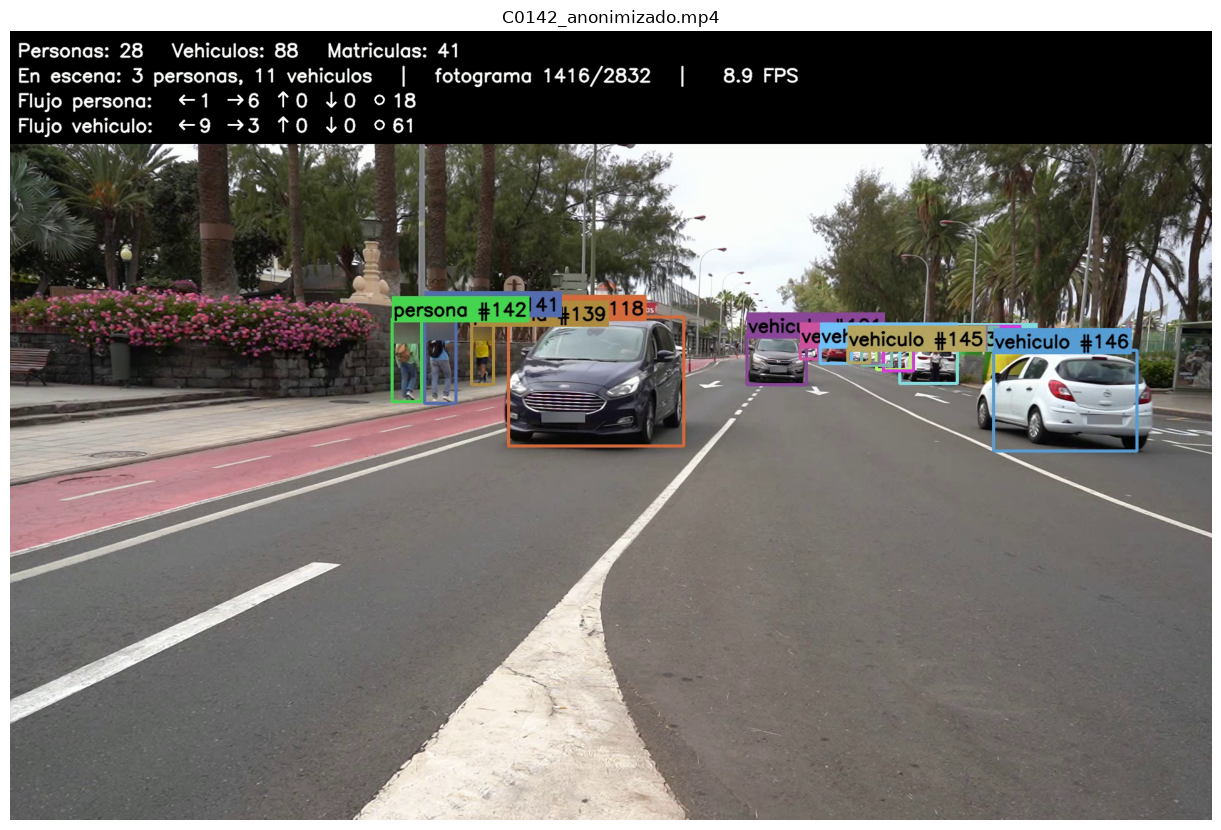

In [36]:
show_frame(output_paths(VIDEO, "anonimizado")["mp4"])

Reproducción del vídeo guardado:

In [ ]:
play_video(output_paths(VIDEO, "anonimizado")["mp4"])

## 7.2. Vídeo 2: detección y OCR

Se sigue el mismo _pipeline_ que en el video anterior pero, en lugar de desenfocar las matrículas, se dibuja su _bounding box_ y se pasa a PaddleOCR para que lea su texto. Para cada vehículo, se muestra la lectura válida más repetida hasta el momento (ver [5.3](#53-lectura-de-cada-vehículo)):

In [38]:
ocr_summary = process_video(VIDEO, "ocr", render_ocr, reader=reader)
print_summary(ocr_summary)

Se reutiliza results\video\C0142_ocr.mp4 (FORCE = True para volver a procesarlo)
2832 fotogramas a 9.6 FPS de media
Objetos distintos: {'vehiculo': 186, 'persona': 60}
Vehículos con matrícula: 89
Lecturas: {'1': '3324H2C', '27': '190290', '50': '5746', '29': '3713LKC', '56': '7132', '82': 'BSNES', '71': '0848MCG', '108': '96291', '72': '6713HCR', '110': '2914FGN', '118': '9786LCF', '146': '10216H2X', '101': '0053JFM', '152': '0285FKZ', '148': '3902FXD', '151': '3685KWM', '170': '9059LYY', '193': '8536LKJ', '192': '5695LTR', '232': '13823', '235': '1770JYG', '272': '7339LG6', '271': '8098JXM', '297': 'GC5273CM', '299': '5143LCY', '292': '1965KBP', '305': '9233', '326': '5017H00'}


,izquierda,derecha,arriba,abajo,parado
persona,6,12,0,0,42
vehiculo,31,9,0,0,146


Fotograma del vídeo guardado:

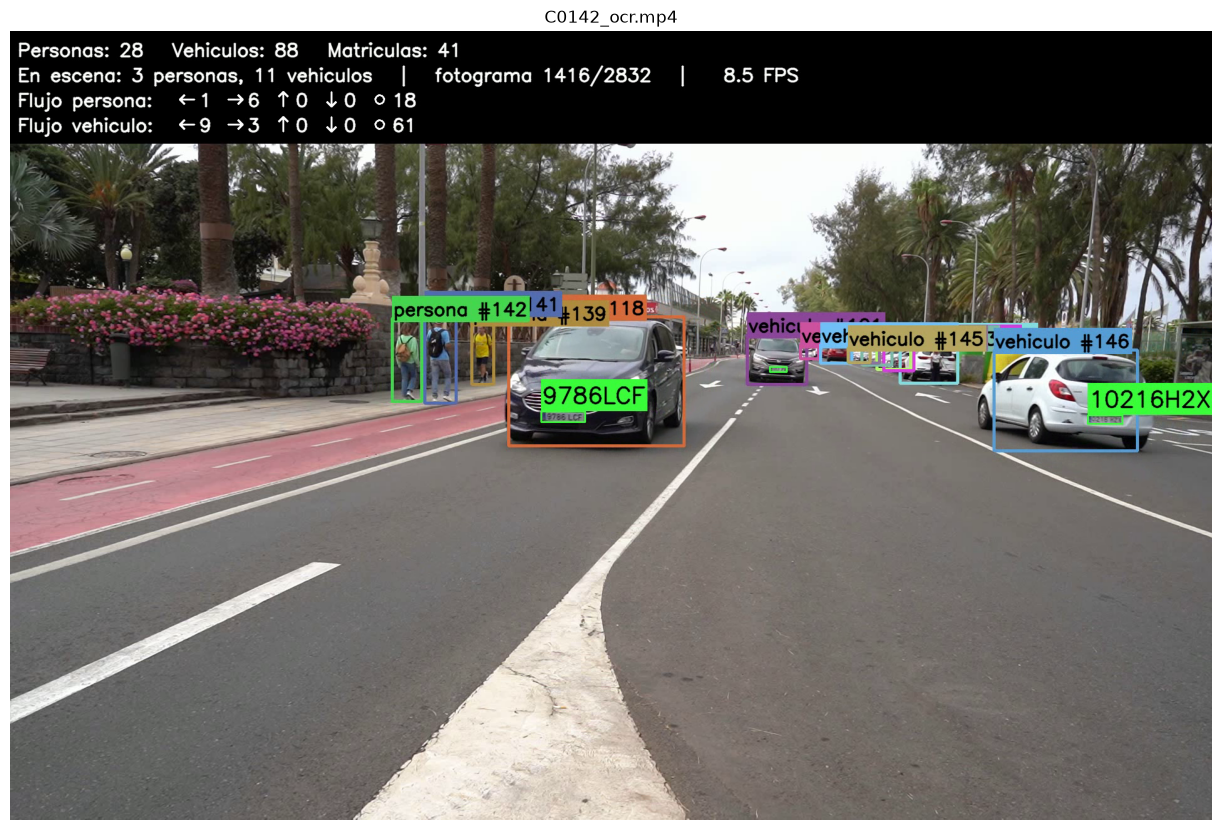

In [39]:
show_frame(output_paths(VIDEO, "ocr")["mp4"])

Reproducción del vídeo guardado:

In [ ]:
play_video(output_paths(VIDEO, "ocr")["mp4"])

## 9. Conclusiones

El modelo desarrollado procesa el vídeo de _test_ y permite detectar a personas, vehículos y matrículas. Los resultados de las funcionalidades implementadas se resumen en:

- **Detección y seguimiento:** las personas y los vehículos cercanos se detectan y siguen de forma estable. Los problemas se concentran en los objetos lejanos: al ser muy pequeños, el _tracker_ los pierde y les asigna identificadores nuevos, lo que infla el recuento de objetos distintos.
- **Flujo:** la dirección se calcula con el desplazamiento en la imagen, que no tiene en cuenta la perspectiva. Los objetos que avanzan por la calle, acercándose o alejándose de la cámara, se mueven en diagonal y se cuentan como movimientos laterales, y los objetos lejanos que apenas se mueven en la imagen se cuentan como parados.
- **Matrículas:** se detectan la gran mayoría de los vehículos, y se alcanzan lecturas fiables siempre y cuando la resolución de la matrícula sea manejable. Las matrículas muy pequeñas y lejanas tienen dificultades en ser leídas.
- **Anonimización:** el desenfoque es suficiente para que el OCR no pueda leer las matrículas anonimizadas. También permite tapar las caras de los peatones correctamente.
- **Velocidad:** el sistema no funciona en tiempo real, pero consigue una velocidad asumible, procesando a unos 9.7 FPS.